In [1]:
# Importing Libraries

import pandas as pd
import numpy as np
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

In [2]:
# Loading datasets

df = pd.read_csv('sales_data-selected-columns.csv')

In [3]:
df

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0
...,...,...,...,...,...,...,...,...,...,...
75995,2024-01-30,S005,P0016,Toys,North,233,63,0,29.80,5
75996,2024-01-30,S005,P0017,Toys,North,137,115,141,42.92,5
75997,2024-01-30,S005,P0018,Clothing,North,197,44,0,17.81,10
75998,2024-01-30,S005,P0019,Furniture,North,125,58,0,151.72,0


In [4]:
# Datasets Inspection
# Checking the First 5 rows

df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0


In [5]:
# Datasets Inspection
# Checking the Last 5 rows

df.tail()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount
75995,2024-01-30,S005,P0016,Toys,North,233,63,0,29.80,5
75996,2024-01-30,S005,P0017,Toys,North,137,115,141,42.92,5
75997,2024-01-30,S005,P0018,Clothing,North,197,44,0,17.81,10
75998,2024-01-30,S005,P0019,Furniture,North,125,58,0,151.72,0
75999,2024-01-30,S005,P0020,Toys,North,126,63,59,25.78,10


In [6]:
# Checking the shape of the dataset

df.shape

(76000, 10)

In [7]:
# Checking the datatype of each column

df.dtypes

Date                object
Store ID            object
Product ID          object
Category            object
Region              object
Inventory Level      int64
Units Sold           int64
Units Ordered        int64
Price              float64
Discount             int64
dtype: object

In [8]:
# Checking the Dataset info

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Date             76000 non-null  object 
 1   Store ID         76000 non-null  object 
 2   Product ID       76000 non-null  object 
 3   Category         76000 non-null  object 
 4   Region           76000 non-null  object 
 5   Inventory Level  76000 non-null  int64  
 6   Units Sold       76000 non-null  int64  
 7   Units Ordered    76000 non-null  int64  
 8   Price            76000 non-null  float64
 9   Discount         76000 non-null  int64  
dtypes: float64(1), int64(4), object(5)
memory usage: 5.8+ MB


In [9]:
# Checking the column names

df.columns

Index(['Date', 'Store ID', 'Product ID', 'Category', 'Region',
       'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount'],
      dtype='object')

In [10]:
# Checking missing values

df.isnull().sum()

Date               0
Store ID           0
Product ID         0
Category           0
Region             0
Inventory Level    0
Units Sold         0
Units Ordered      0
Price              0
Discount           0
dtype: int64

In [11]:
# Checking for duplicate rows

df.duplicated().sum()

np.int64(0)

In [12]:
# Checking for Value counts of each column

for col in df.columns:
    print("=" * 40)
    print(f"Value counts for column: {col}")
    print("=" * 40)
    print(df[col].value_counts())

Value counts for column: Date
Date
2022-01-01    100
2023-05-26    100
2023-05-17    100
2023-05-18    100
2023-05-19    100
             ... 
2022-09-13    100
2022-09-14    100
2022-09-15    100
2022-09-16    100
2024-01-30    100
Name: count, Length: 760, dtype: int64
Value counts for column: Store ID
Store ID
S001    15200
S002    15200
S003    15200
S004    15200
S005    15200
Name: count, dtype: int64
Value counts for column: Product ID
Product ID
P0001    3800
P0002    3800
P0019    3800
P0018    3800
P0017    3800
P0016    3800
P0015    3800
P0014    3800
P0013    3800
P0012    3800
P0011    3800
P0010    3800
P0009    3800
P0008    3800
P0007    3800
P0006    3800
P0005    3800
P0004    3800
P0003    3800
P0020    3800
Name: count, dtype: int64
Value counts for column: Category
Category
Groceries      30400
Furniture      13680
Clothing       12160
Toys           10640
Electronics     9120
Name: count, dtype: int64
Value counts for column: Region
Region
North    30400
South   

Observation

1. We have 76000 rows and 10 columns in this dataset
2. Date and Time columns should be converted to DateTime data type
3  All other columns has the right data type
4. The column names reflects the right data in them
5. There are no missing values recorded in the dataset
6. There are also no duplicate rows in the dataset
7. 
Therefore, We will convert the Date columns to DateTime data type

DATA CLEANING

In [13]:
# Convert Date and Time columns from Object to DateTime data type

df['Date'] = pd.to_datetime(df['Date'])

In [14]:
# Confirming if the changes has been made

df.dtypes

Date               datetime64[ns]
Store ID                   object
Product ID                 object
Category                   object
Region                     object
Inventory Level             int64
Units Sold                  int64
Units Ordered               int64
Price                     float64
Discount                    int64
dtype: object

Data Visualization

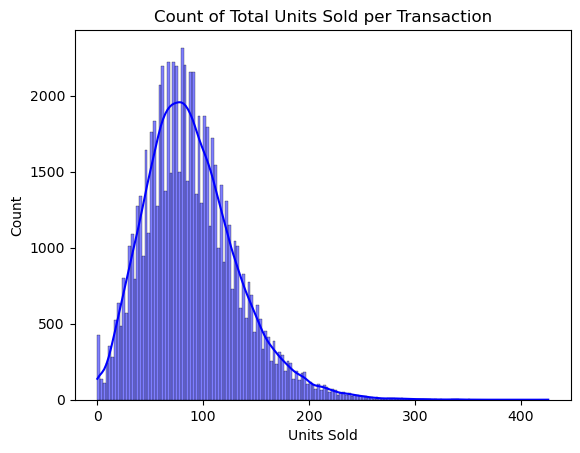

In [18]:
# Target Variable Distribution

plt.figure()
sns.histplot(df['Units Sold'], kde=True, color='blue')
plt.title('Count of Total Units Sold per Transaction')
plt.xlabel('Units Sold')
plt.show()

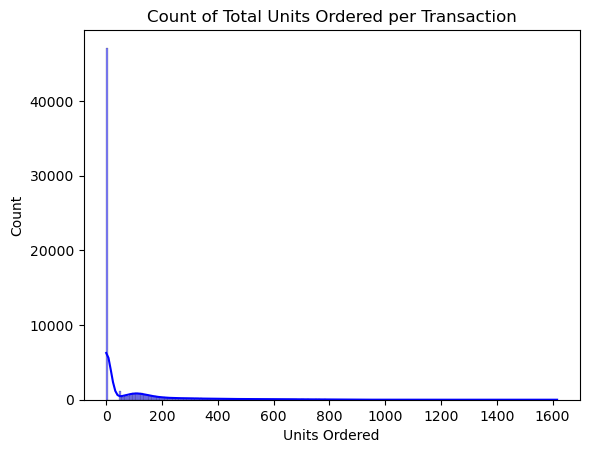

In [19]:
# Target Variable Distribution

plt.figure()
sns.histplot(df['Units Ordered'], kde=True, color='blue')
plt.title('Count of Total Units Ordered per Transaction')
plt.xlabel('Units Ordered')
plt.show()